# PH22007: Scientific Computing in Python Coursework: Population Dynamics

## Part 1: Rabbits and Foxes

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

In [2]:
a = 1.0 # birth rate of rabbits
b = 0.1 # the predation rate
c = 0.5 # natural death rate of foxes
d = 0.02 # rate the foxes are cereated from eating rabbits

In [3]:
t_0 = 0.0 # initial time
t_f = 100 # final time
h = 0.01 # step size
initial_conditions = [100, 20] # initial conditions of rabbits and foxes

In [4]:
def F(t, S): # defining a function for the lotka-volterra equation
    x, y = S  # making S an array with [x, y]
    dx_dt = a * x - b * x * y # rate of change of rabbits
    dy_dt = d * x * y - c * y # rate of change of foxes
    return np.array([dx_dt, dy_dt])

In [5]:
tlist = np.arange(t_0, t_f , h) # making an array for time
S_euler = np.zeros((len(tlist), 2)) # creating an array fo zeroes
S_euler[0] = initial_conditions

In [6]:
# euler method iteration
for i in range(0, len(tlist)-1):
    S_euler[i+1] = S_euler[i] + h * F(tlist[i], S_euler[i])

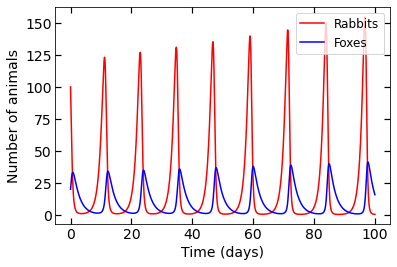

In [7]:
# making a plot of the popualtions of rabbits and foxes against time, using the euler method
plt.plot(tlist, S_euler[:, 0], 'r', label='Rabbits')
plt.plot(tlist, S_euler[:, 1], 'b', label='Foxes')
plt.xlabel('Time (days)', fontsize=14)
plt.ylabel('Number of animals', fontsize=14)
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.legend(loc='upper right', fontsize=12)
plt.savefig('Populations_euler.pdf')
plt.show()

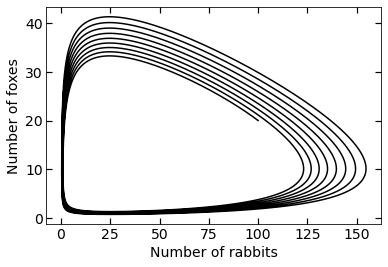

In [8]:
# making a plot of the trajectories of rabbits and foxes against time, using the euler method
plt.plot(S_euler[:, 0], S_euler[:, 1], 'black')
plt.xlabel('Number of rabbits', fontsize=14)
plt.ylabel('Number of foxes', fontsize=14)
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.savefig('Trajectories_euler.pdf')
plt.show()

In [9]:
# solving the inital value problem for the rabbits and foxes
sol = solve_ivp(F, [t_0, t_f], initial_conditions, t_eval=tlist, max_step=h)

In [10]:
t = sol.t # times
x = sol.y[0] # rabbits
y = sol.y[1] # foxes

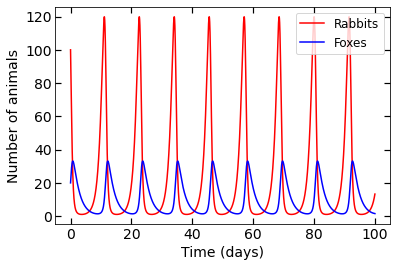

In [11]:
# making a plot of the popualtions of rabbits and foxes against time, using the RK4 method
plt.plot(t, sol.y[0], 'r', label='Rabbits')
plt.plot(t, y, 'b', label='Foxes')
plt.xlabel('Time (days)', fontsize=14)
plt.ylabel('Number of animals', fontsize=14)
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.legend(loc='upper right', fontsize=12)
plt.savefig('Populations_RK4.pdf')
plt.show()

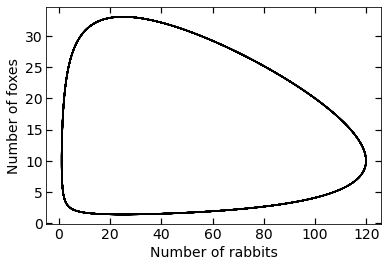

In [12]:
# making a plot of the trajectories of rabbits and foxes against time, using the RK4 method
plt.plot(x, y, 'black')
plt.xlabel('Number of rabbits', fontsize=14)
plt.ylabel('Number of foxes', fontsize=14)
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.show()

In [13]:
peaks, _ = find_peaks(x) # finding the peaks in x(t)
t_peaks = t[peaks]

In [14]:
T_values = np.diff(t_peaks) # calculating the difference between consecutive elements in the t_peaks array
t_period = np.mean(T_values) # calculating the mean time period

In [15]:
print("Peak times:", t_peaks)
print(f"Mean time period T = {t_period:.2f} days")

Peak times: [11.09 22.58 34.07 45.55 57.04 68.52 80.01 91.49]
Mean time period T = 11.49 days


In [16]:
# values for the first and second peaks
t1 = t_peaks[0]
t2 = t_peaks[1]
x1 = x[peaks[0]]
y1 = y[peaks[0]]
x2 = x[peaks[1]]
y2 = y[peaks[1]]

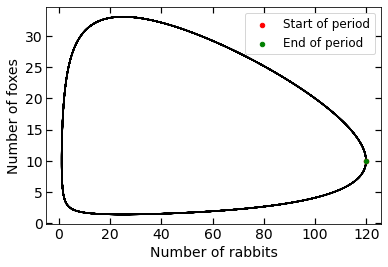

In [17]:
# including the beginning and end of time period on the trajectory plot
plt.plot(x, y, 'black')
plt.xlabel('Number of rabbits', fontsize=14)
plt.ylabel('Number of foxes', fontsize=14)
plt.scatter(x1, y1, c='red', s=20, zorder=5, label='Start of period')
plt.scatter(x2, y2, c='green', s=20, zorder=5, label='End of period')
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.legend(loc='upper right', fontsize=12) 
plt.savefig('Trajectroies_RK4.pdf')
plt.show()

## Part 2: Zombie Outbreak!

In [18]:
a1 = 0.0 # natural birth rate of humans
b1 = 10**-4 # natural death rate of humans
c1 = 9.5*(10**-3) # the zombification rate
d1 = 10**-4 # the zombie destruction rate
e1 = 10**-4 # the resurrecton rate

In [19]:
t_init = 0 # initial time
t_fin = 5 # final time
h1 = 0.1 # step size
initial_conditions1 = [1000, 5, 0] # initial conditions of humans, zombies and the dead

In [20]:
def zom_fun(t, S): # defining a function for the lotka-volterra system
    H, Z, D = S  # Making S an array with [H, Z, D]
    dH_dt = a1 * H - b1 * H - c1 * H * Z # rate of change of humans
    dZ_dt = c1 * H * Z - d1 * H * Z + e1 * D # rate of change of zombies
    dD_dt = b1 * H + d1 * H * Z - e1 * D # rate of change of the dead
    return np.array([dH_dt, dZ_dt, dD_dt])

In [21]:
tlist1 = np.arange(t_init, t_fin , h1) # making an array for the time

In [22]:
# solving the initial value problem for the zombie outbreak
sol_zom = solve_ivp(zom_fun, [t_init, t_fin], initial_conditions1, t_eval=tlist1)

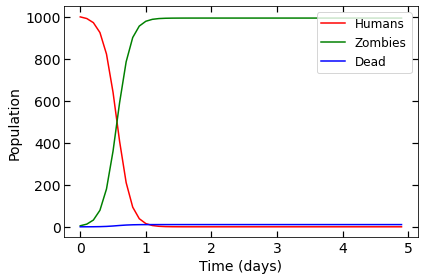

In [23]:
# making a plot of populations of humans, zombies and the dead, using the RK4 method
plt.plot(sol_zom.t, sol_zom.y[0], 'r', label='Humans')
plt.plot(sol_zom.t, sol_zom.y[1], 'g', label='Zombies')
plt.plot(sol_zom.t, sol_zom.y[2], 'b', label='Dead')
plt.xlabel('Time (days)', fontsize=14)
plt.ylabel('Population', fontsize=14)
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.savefig('Zombie_population.pdf')
plt.show()

In [24]:
gamma_values = np.linspace(0.002, 0.02, 60) # creating an array for many different values for gamma, where gamma is the zombification rate

In [25]:
outbreak_times = []  # storing the outbreak times for each gamma value

for gamma in gamma_values:
    def zom_fun1(t, S):
        H, Z, D = S
        dH_dt = a1*H - b1*H - gamma*H*Z
        dZ_dt = gamma*H*Z - d1*H*Z + e1*D
        dD_dt = b1*H + d1*H*Z - e1*D
        return [dH_dt, dZ_dt, dD_dt]

    sol_zom_vary = solve_ivp(zom_fun1, [t_init, t_fin], initial_conditions1, t_eval=tlist1) # solving the initial value problem for new function where zombification rate is varied

    H = sol_zom_vary.y[0]
    Z = sol_zom_vary.y[1]
    D = sol_zom_vary.y[2]

    outbreak_time = None     
    for t, h, z in zip(sol_zom_vary.t, H, Z): # finding the first time where Z >= H
        if z >= h:
            outbreak_time = t
            break

    outbreak_times.append(outbreak_time) # making an array for the outbreak times

In [26]:
# making an appropriate fit for the data, where k1 and k2 are constants to be found and g is the zombification rate
def fit(g, k1, k2):
    return k1 / g + k2

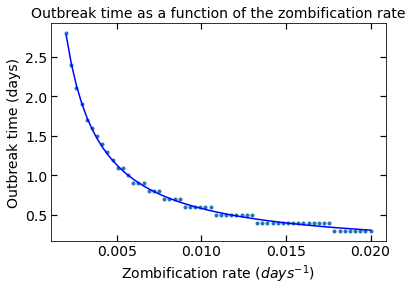

In [27]:
# making a plot of the outbreak time against the zombification rate
plt.plot(gamma_values, outbreak_times, '.')
popt, pcov = curve_fit(fit, gamma_values, outbreak_times) # fit curve
plt.plot(gamma_values, fit(gamma_values, *popt), 'b')
plt.xlabel('Zombification rate ($days^{-1})$', fontsize=14)
plt.ylabel('Outbreak time (days)', fontsize=14)
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.title('Outbreak time as a function of the zombification rate', fontsize=14)
plt.savefig('Zombification_inverse.pdf')
plt.show()
plt.close()

In [28]:
print(f"Fitted parameters: k1 = {popt[0]} and k2 = {popt[1]}")

Fitted parameters: k1 = 0.005482766542490028 and k2 = 0.034623243348754947


## Part 3: Extending the Model

In [29]:
f = 1.0  # maximum cure rate
const = 1.0  # speed vaccine is given out

In [30]:
# cure rate as a function of time
def f_t(t):
    return f * (1 - np.exp(-const * t))

In [31]:
def zom_cure(t, S): # defining a function for the lotka-volterra system
    H, Z, D = S
    f = f_t(t)
    dH_dt = a1 * H - b1 * H - c1 * H * Z + f * Z
    dZ_dt = c1 * H * Z - d1 * H * Z + e1 * D - f * Z
    dD_dt = b1 * H + d1 * H * Z - e1 * D
    return np.array([dH_dt, dZ_dt, dD_dt])

In [32]:
# solving the inital value problem
sol_cure = solve_ivp(zom_cure, [t_init, t_fin], initial_conditions1, t_eval=tlist1)

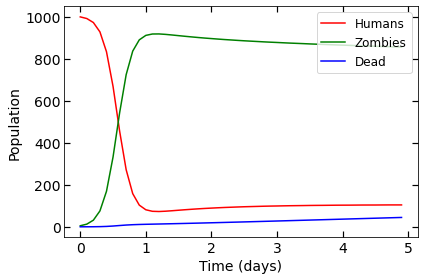

In [33]:
# plot of populations of humans, zombies and the dead when a cure is introduced
plt.plot(sol_cure.t, sol_cure.y[0], 'r', label='Humans')
plt.plot(sol_cure.t, sol_cure.y[1], 'g', label='Zombies')
plt.plot(sol_cure.t, sol_cure.y[2], 'b', label='Dead')
plt.xlabel('Time (days)', fontsize=14)
plt.ylabel('Population', fontsize=14)
plt.tick_params(which='major', direction='in', top=True, right=True, length=6, width=1.2, labelsize=14)
plt.legend(loc='upper right', fontsize=12)
plt.tight_layout()
plt.savefig('Zombie_cure.pdf')
plt.show()